In [2]:
from src.mesh_setup import generate_mesh
meshes = []
mesh_sizes = [1/8, 1/16, 1/32, 1/64, 1/128, 1/256]
for mesh_size in mesh_sizes:
    meshes.append(generate_mesh(mesh_size))

Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : Done meshing 1D (Wall 0.000177184s, CPU 0.000147s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.00293583s, CPU 0.003288s)
Info    : 98 nodes 198 elements
Info    : Done generating mesh
Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : Done meshing 1D (Wall 0.000181052s, CPU 0.000262s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.00842457s, CPU 0.008404s)
Info    : 338 nodes 678 elements
Info    : Done generating mesh
Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Inf

In [2]:
from dolfinx.fem.petsc import LinearProblem
from src.problem_builder import setup_problem
import time

solve_times = []
iterations = []

for mesh in meshes:
    a, L, bcs = setup_problem(mesh, "Lagrange", "Lagrange", 2, 1)
    problem = LinearProblem(
    a,
    L,
    bcs=bcs,
    kind="nest",
    petsc_options_prefix="cavity",
    petsc_options= {
        "ksp_type": "preonly",
        "pc_type": "lu",
        "pc_factor_mat_solver_type": "mumps"
    } 
    )
    start_time = time.perf_counter()
    problem.solve()
    solve_time = time.perf_counter() - start_time
    solve_times.append(solve_time)
    iterations.append(problem.solver.getIterationNumber())

Info    : Done setting up problem
Info    : Done setting up problem
Info    : Done setting up problem
Info    : Done setting up problem
Info    : Done setting up problem
Info    : Done setting up problem


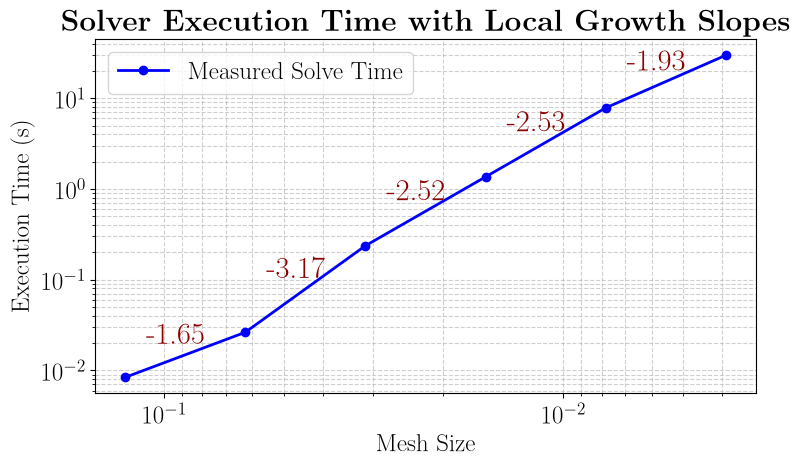

In [6]:
import matplotlib.pyplot as plt
import numpy as np

solve_times = np.array(solve_times)
mesh_sizes = np.array(mesh_sizes)
iterations = np.array(iterations)

# Compute local log-log slopes: slope = Δ(log y) / Δ(log x)
log_x = np.log10(mesh_sizes)
log_y = np.log10(solve_times)
slopes = (log_y[1:] - log_y[:-1]) / (log_x[1:] - log_x[:-1])

plt.figure(figsize=(8, 5))
plt.loglog(mesh_sizes, solve_times, 'o-', color='b', lw=2, label='Measured Solve Time')

# Plot slope numbers between consecutive points
for i in range(len(slopes)):
    # Midpoint coordinates in log space (geometric mean for correct visual placement)
    x_mid = 10 ** ((log_x[i] + log_x[i+1]) / 2)
    y_mid = 10 ** ((log_y[i] + log_y[i+1]) / 2)
    
    # Annotate slope above the segment
    plt.annotate(
        f"{slopes[i]:.2f}",
        xy=(x_mid, y_mid),
        xytext=(-7, 8),
        textcoords="offset points",
        ha="center",
        fontsize=22,
        fontweight="bold",
        color="darkred"
    )

plt.gca().invert_xaxis()
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern"],
    "font.size": 18,
})
plt.xlabel("Mesh Size")
plt.ylabel("Execution Time (s)")
plt.title(r"\textbf{Solver Execution Time with Local Growth Slopes}")
plt.grid(True, which="both", linestyle="--", alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig("/home/lukasl/Documents/vienna_uni/computational_analysis_seminar/comp_math_presentation/images/execution_time_LU.png", dpi=300, bbox_inches="tight", transparent=True)
plt.show()

In [7]:
from dolfinx.fem.petsc import LinearProblem
from src.problem_builder import setup_problem
import time

solve_times = []
iterations = []

for mesh in meshes:
    a, L, bcs = setup_problem(mesh, "Lagrange", "Lagrange", 2, 1)
    problem = LinearProblem(
    a,
    L,
    bcs=bcs,
    kind="nest",
    petsc_options_prefix="cavity",
    petsc_options= {
        "ksp_type": "minres",
        "pc_type": "none",
    } 
    )
    start_time = time.perf_counter()
    problem.solve()
    solve_time = time.perf_counter() - start_time
    solve_times.append(solve_time)
    iterations.append(problem.solver.getIterationNumber())

Info    : Done setting up problem
Info    : Done setting up problem
Info    : Done setting up problem
Info    : Done setting up problem
Info    : Done setting up problem
Info    : Done setting up problem


[ 279  521  957 1664 2760 3686]
[1.63904060e-02 7.91340290e-02 4.98795772e-01 3.33792380e+00
 2.03517474e+01 1.13906934e+02]


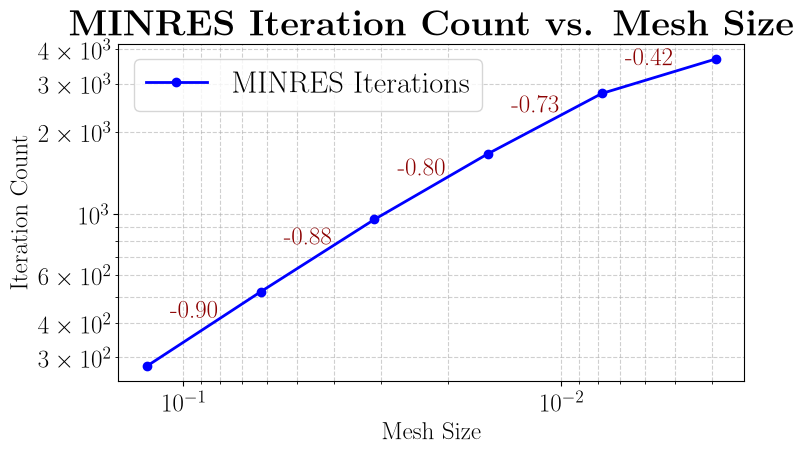

In [9]:
import matplotlib.pyplot as plt
import numpy as np

solve_times = np.array(solve_times)
mesh_sizes = np.array(mesh_sizes)
iterations = np.array(iterations)

# Compute local log-log slopes: slope = Δ(log y) / Δ(log x)
log_x = np.log10(mesh_sizes)
log_y = np.log10(iterations)
slopes = (log_y[1:] - log_y[:-1]) / (log_x[1:] - log_x[:-1])

plt.figure(figsize=(8, 5))
plt.loglog(mesh_sizes, iterations, 'o-', color='b', lw=2, label='MINRES Iterations')

# Plot slope numbers between consecutive points
for i in range(len(slopes)):
    # Midpoint coordinates in log space (geometric mean for correct visual placement)
    x_mid = 10 ** ((log_x[i] + log_x[i+1]) / 2)
    y_mid = 10 ** ((log_y[i] + log_y[i+1]) / 2)
    
    # Annotate slope above the segment
    plt.annotate(
        f"{slopes[i]:.2f}",
        xy=(x_mid, y_mid),
        xytext=(-7, 8),
        textcoords="offset points",
        ha="center",
        fontsize=18,
        fontweight="bold",
        color="darkred"
    )

print(iterations)
print(solve_times)
plt.gca().invert_xaxis()
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern"],
    "font.size": 22,
})
plt.xlabel("Mesh Size")
plt.ylabel("Iteration Count")
plt.title(r"\textbf{MINRES Iteration Count vs. Mesh Size}")
plt.grid(True, which="both", linestyle="--", alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig("/home/lukasl/Documents/vienna_uni/computational_analysis_seminar/comp_math_presentation/images/execution_time_MINRES.png", dpi=300, bbox_inches="tight", transparent=True)
plt.show()

In [18]:
from dolfinx.fem.petsc import LinearProblem
from src.problem_builder import setup_problem
import time

solve_times = []
iterations = []

for mesh in meshes:
    a, L, bcs = setup_problem(mesh, "Lagrange", "Lagrange", 2, 1)
    problem = LinearProblem(
    a,
    L,
    bcs=bcs,
    kind="nest",
    petsc_options_prefix="cavity",
    petsc_options= {
        "ksp_type": "minres",
        "pc_type": "fieldsplit",

        "pc_fieldsplit_type": "additive",

        "fieldsplit_0_ksp_type": "preonly",
        "fieldsplit_0_pc_type": "gamg",

        "fieldsplit_1_ksp_type": "preonly",
        "fieldsplit_1_pc_type": "jacobi"
    } 
    )
    start_time = time.perf_counter()
    problem.solve()
    solve_time = time.perf_counter() - start_time
    solve_times.append(solve_time)
    iterations.append(problem.solver.getIterationNumber())

Info    : Done setting up problem
Info    : Done setting up problem
Info    : Done setting up problem
Info    : Done setting up problem
Info    : Done setting up problem
Info    : Done setting up problem


[ 75 101 121 125 127 101]
[1.53390530e-02 6.37501220e-02 2.30170433e-01 1.23332966e+00
 5.34393424e+00 1.94163611e+01]


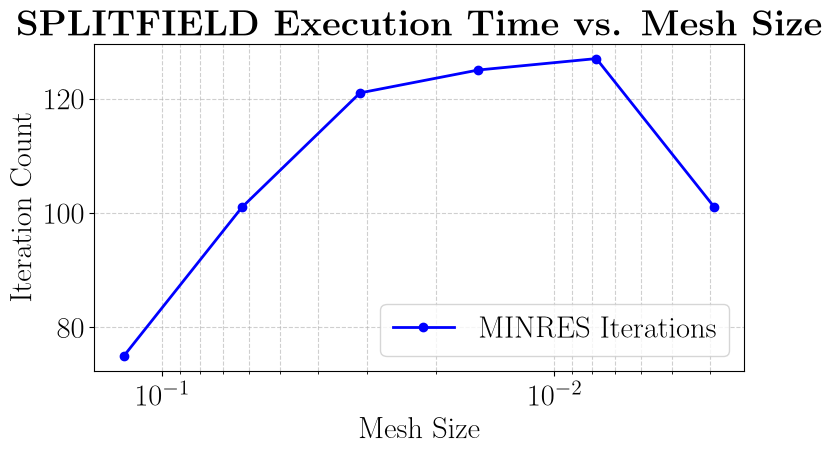

In [19]:
import matplotlib.pyplot as plt
import numpy as np

solve_times = np.array(solve_times)
mesh_sizes = np.array(mesh_sizes)
iterations = np.array(iterations)
print(iterations)
print(solve_times)

plt.figure(figsize=(8, 5))
plt.semilogx(mesh_sizes, iterations, 'o-', color='b', lw=2, label='MINRES Iterations')


plt.gca().invert_xaxis()
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern"],
    "font.size": 22,
})
plt.xlabel("Mesh Size")
plt.ylabel("Iteration Count")
plt.title(r"\textbf{SPLITFIELD Execution Time vs. Mesh Size}")
plt.grid(True, which="both", linestyle="--", alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig("/home/lukasl/Documents/vienna_uni/computational_analysis_seminar/comp_math_presentation/images/execution_time_SPLITFIELD.png", dpi=300, bbox_inches="tight", transparent=True)
plt.show()

In [4]:
import time
import ufl
from petsc4py import PETSc
from dolfinx.fem.petsc import LinearProblem, create_vector
from src.problem_builder import setup_problem
import numpy as np

lu_options = {
    "ksp_type": "preonly",
    "pc_type": "lu",
    "pc_factor_mat_solver_type": "mumps",
    "mat_mumps_icntl_24": 1,   # detect the null pivot (pressure constant)
    "mat_mumps_icntl_25": 0,
    "ksp_error_if_not_converged": True,
}

minres_options = {
    "ksp_type": "minres",
    "ksp_rtol": 1e-8,
    "ksp_error_if_not_converged": True,
    "pc_type": "fieldsplit",
    "pc_fieldsplit_type": "additive",           # block-diagonal preconditioner
    "fieldsplit_0_ksp_type": "preonly",
    "fieldsplit_0_pc_type": "gamg",             # one AMG V-cycle on the velocity block
    "fieldsplit_1_ksp_type": "preonly",
    "fieldsplit_1_pc_type": "jacobi",           # diagonal of the pressure mass matrix
}


def run(meshes, solver="minres"):
    times, iterations, dofs = [], [], []
    for i, mesh_data in enumerate(meshes):
        a, L, bcs = setup_problem(mesh_data, "Lagrange", "Lagrange", 2, 1)
        V = L[0].arguments()[0].ufl_function_space()
        Q = L[1].arguments()[0].ufl_function_space()

        if solver == "lu":
            problem = LinearProblem(a, L, bcs=bcs, kind="mpi",
                                    petsc_options_prefix=f"lu_{i}_",
                                    petsc_options=lu_options)
        else:
            # Preconditioner: velocity block of A, pressure mass matrix
            # (scale it by 1/mu if you use mu != 1)
            p, q = ufl.TrialFunction(Q), ufl.TestFunction(Q)
            P = [[a[0][0], None], [None, p * q * ufl.dx]]
            problem = LinearProblem(a, L, bcs=bcs, P=P, kind="nest",
                                    petsc_options_prefix=f"minres_{i}_",
                                    petsc_options=minres_options)

            # Pressure is only determined up to a constant: attach the null space
            null_vec = create_vector([V, Q], "nest")
            u_ns, p_ns = null_vec.getNestSubVecs()
            u_ns.set(0.0)
            p_ns.set(1.0)
            null_vec.normalize()
            problem.A.setNullSpace(PETSc.NullSpace().create(vectors=[null_vec]))

        start = time.perf_counter()
        problem.solve()
        times.append(time.perf_counter() - start)
        iterations.append(problem.solver.getIterationNumber())
        dofs.append(V.dofmap.index_map.size_global * V.dofmap.index_map_bs
                    + Q.dofmap.index_map.size_global)
    return np.array(times), np.array(iterations), np.array(dofs)


lu_times, _, dofs = run(meshes, "lu")
minres_times, minres_its, _ = run(meshes, "minres")
print("N:         ", dofs)
print("LU time:   ", lu_times)
print("MINRES:    ", minres_times, minres_its)

Info    : Done setting up problem
Info    : Done setting up problem
Info    : Done setting up problem
Info    : Done setting up problem
Info    : Done setting up problem
Info    : Done setting up problem
Info    : Done setting up problem
Info    : Done setting up problem
Info    : Done setting up problem
Info    : Done setting up problem
Info    : Done setting up problem
Info    : Done setting up problem
N:          [   812   2908  11096  43483 172130 685231]
LU time:    [3.54281500e-03 1.44777650e-02 1.14025871e-01 7.00399143e-01
 4.30190889e+00 3.01505696e+01]
MINRES:     [7.90357900e-03 2.75722620e-02 1.16412726e-01 6.15486706e-01
 2.90001024e+00 1.14550761e+01] [62 74 84 87 90 96]


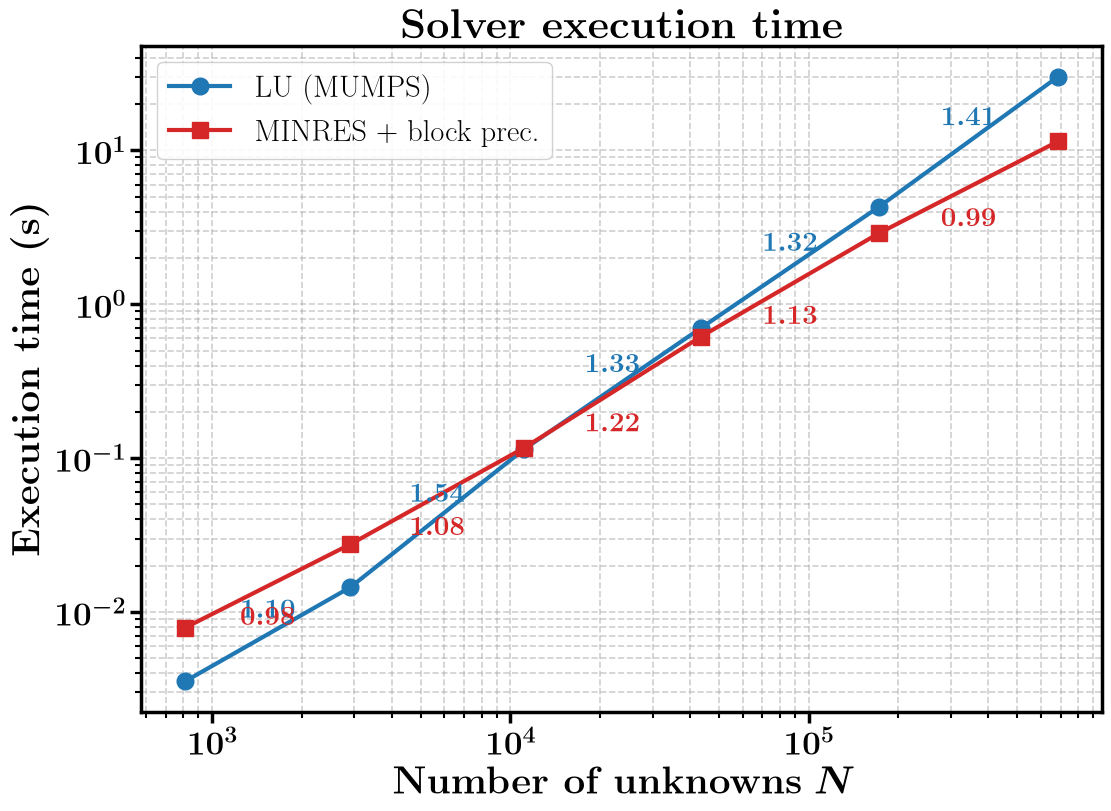

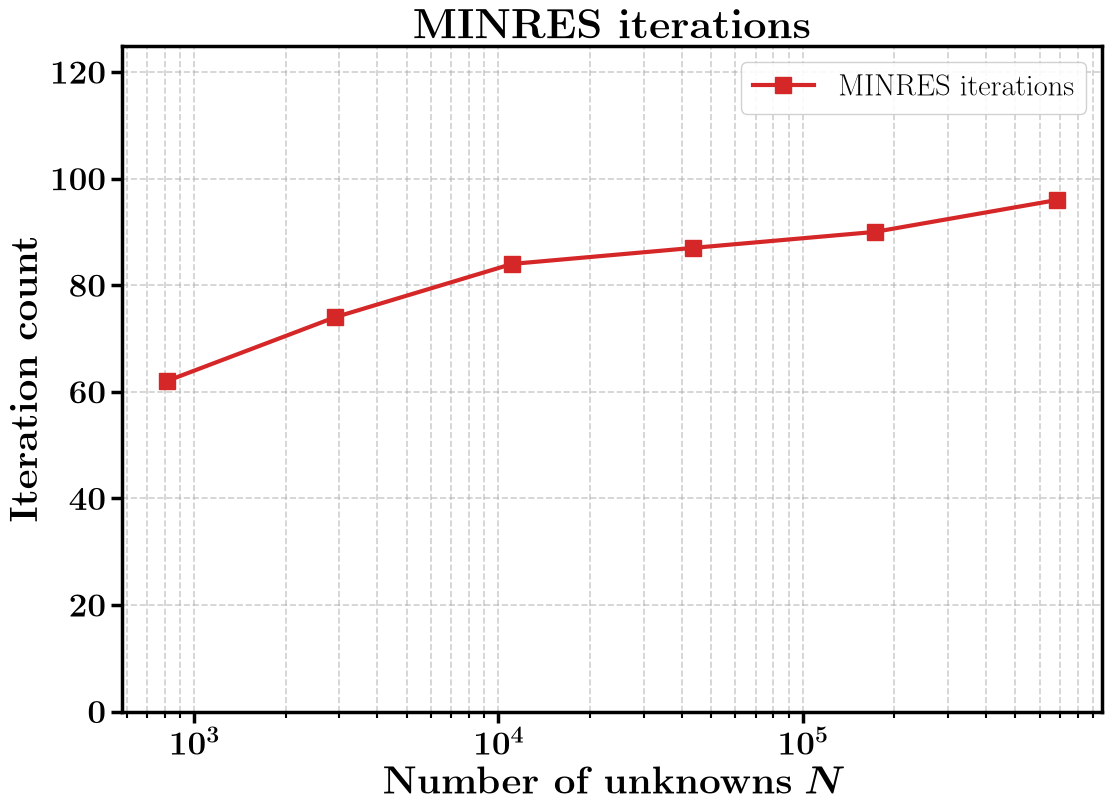

In [7]:
from src.plot_style import apply_style, annotate_slopes, save
apply_style()

fig, ax = plt.subplots(figsize=(11, 8), constrained_layout=True)
ax.loglog(dofs, lu_times, "o-", color="tab:blue", label="LU (MUMPS)")
ax.loglog(dofs, minres_times, "s-", color="tab:red", label="MINRES + block prec.")
annotate_slopes(ax, dofs, lu_times, "tab:blue")
annotate_slopes(ax, dofs, minres_times, "tab:red", offset=(0, -28))
ax.set_xlabel(r"\textbf{Number of unknowns} $N$")
ax.set_ylabel(r"\textbf{Execution time (s)}")
ax.set_title(r"\textbf{Solver execution time}")
ax.legend()
save(fig, "execution_time.png")
plt.show()

fig, ax = plt.subplots(figsize=(11, 8), constrained_layout=True)
ax.semilogx(dofs, minres_its, "s-", color="tab:red", label="MINRES iterations")
ax.set_ylim(0, 1.3 * minres_its.max())
ax.set_xlabel(r"\textbf{Number of unknowns} $N$")
ax.set_ylabel(r"\textbf{Iteration count}")
ax.set_title(r"\textbf{MINRES iterations}")
ax.legend()
save(fig, "iterations_MINRES.png")
plt.show()